# Klasifikasi Biner: Banknote Authentication

Dataset Banknote Authentication memuat fitur statistik yang diekstraksi dari citra uang kertas menggunakan Wavelet Transform untuk membedakan spesimen uang kertas asli dan uang kertas palsu.

- Nama dataset: Banknote Authentication
- Sumber data: UCI Machine Learning Repository (ID: 267)
- Link dataset: https://archive.ics.uci.edu/dataset/267/banknote+authentication
- Dimensi data: 1.372 baris dan 5 kolom (4 fitur kontinu dan 1 kolom target)
- Variabel target: Kolom `class` dengan nilai 0 (asli) dan 1 (palsu)

In [1]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

banknote = fetch_ucirepo(id=267)
X = banknote.data.features
y = banknote.data.targets
df = pd.concat([X, y], axis=1)

print("Shape data:", df.shape)
display(df.head())
print("\nTipe data:")
print(df.dtypes)

Shape data: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



Tipe data:
variance    float64
skewness    float64
curtosis    float64
entropy     float64
class         int64
dtype: object


Nilai unik target: [np.int64(0), np.int64(1)] => biner: True

Distribusi kelas:
class
0 (asli)     762
1 (palsu)    610
Name: count, dtype: int64


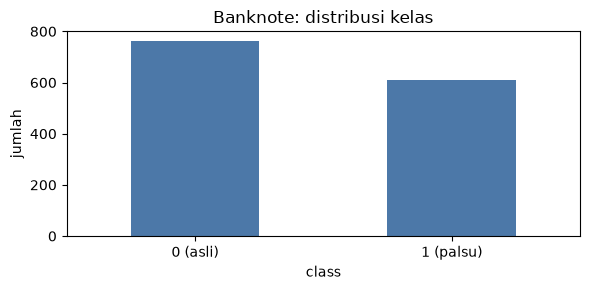

In [2]:
import matplotlib.pyplot as plt

def plot_dist(y, title, rot=0):
    ax = pd.Series(y).value_counts().sort_index().plot(kind="bar", figsize=(6, 3), color="#4C78A8")
    ax.set_title(title)
    ax.set_ylabel("jumlah")
    plt.xticks(rotation=rot)
    plt.tight_layout()
    plt.show()

target_col = "class"

print("Nilai unik target:", sorted(df[target_col].unique()), "=> biner:", df[target_col].nunique() == 2)
print("\nDistribusi kelas:")
print(df[target_col].value_counts().rename({0: "0 (asli)", 1: "1 (palsu)"}))
plot_dist(df[target_col].replace({0: "0 (asli)", 1: "1 (palsu)"}), "Banknote: distribusi kelas")

In [3]:
assert df[target_col].nunique() == 2, "Nilai unik target harus berjumlah 2"
assert set(df[target_col].unique()) == {0, 1}, "Label target harus {0, 1}"
assert df[target_col].isnull().sum() == 0, "Target mengandung nilai null"
assert df.shape == (1372, 5), f"Bentuk dataframe tidak sesuai: {df.shape}"

print("Semua verifikasi lolos.")

Semua verifikasi lolos.


## Kesimpulan

Dataset Banknote Authentication merupakan klasifikasi biner dengan kolom target `class` yang memuat tepat 2 nilai: 0 untuk uang asli (762 baris) dan 1 untuk uang palsu (610 baris). Setiap baris data merepresentasikan satu spesimen tanpa tumpang tindih target.